# 1. Geospatial datasets

In introduction, we saw example where every image is already split and prepared. Each has its class. But usually, we operate at a larger scale of images that are not pre-tiled, and the desired output comes at pixel level (a mask). This can be either raster or vector data in different resolutions and potentially different coordinate systems. TorchGeo's job is to make these things cooperate nicely, without the need for us to do every reprojection, tiling, etc. manually.

So in this notebook, we will explore how to use TorchGeo to work with custom "real" geospatial datasets.
Our area of interest is the region around FRI campus. We will work with 2 time-steps, one from year 2018 and one from 2024.
The data includes:
- Orthophoto at 0.5m resolution
- Vector building data from cadastre, filtered by the "year" to determine what buildings are new (a bit noisy)
- Sentinel 2 images of same location at years 2018 and 2024 at 10m resolution.
- Change masks: rasterised masks indicating new buildings from 2018 to 2024.

TorchGeo offers various dataset, dataloader and sampler classes to enable all of this. In the next cell, we will import the necessary classes from TorchGeo that we'll later see how to use. Many things are already implemented and ready to use, but we will also see how to create our own custom dataset.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
from shapely.geometry import box
from torch.utils.data import DataLoader

from torchgeo.datasets import IntersectionDataset, RasterDataset, Sentinel2, VectorDataset
from torchgeo.samplers import GriddedPatchSampler, RandomPatchSampler

# this is where our pre-prepared data is stored
# TODO
PREPARED = Path('../data/prepared')

## Orthophotos

A `RasterDataset` is used when working with raster files and it is a subclass of a `GeoDataset` which is a base class for any data with geospatial info. TorchGeo also has many benchmarks (which are `NonGeoDatasets`) for some of the academic practices if you are interested in that.

A good thing here is that we did not even need to do any fancy loading code, we just point the class to tif and it does its thing :D. It is well capable of many tricks, like band selection, transforms, time series support, so it's good idea to really check if this fits our needs before we go and write a custom loading. Even then, we just derive a subclass of this and add the custom logic while keeping all the other stuff compatible, such as reprojections etc.

Our files are in the folder given above in `rgb` dir with name `2018.tif` and `2024.tif`.

In [4]:
before = RasterDataset(PREPARED / 'rgb/2018.tif')
after = RasterDataset(PREPARED / 'rgb/2024.tif')

print(before.crs.name, before.res)
before.index

ETRS_1989_Slovenia_TM (0.5, 0.5)


,filepath,geometry
datetime,,
"[1677-09-21 00:12:43.145224193, 2262-04-11 23:47:16.854775807]",../data/prepared/rgb/2018.tif,"POLYGON ((459500 100000, 459500 103000, 457250..."


Datasets are usually indexed by numeric "index" :) but in this case, since this is a GeoDataset we can also index with coordinates. Our coordinates are in metres (or at least to me it's close enough, don't be too mad if it's not 100% true) as this is Slovenian natioanl CRS D96/TM. Let's cut a small patch around FRI with indices: `458700:459000, 101200:101400`.

torch.Size([3, 400, 600])


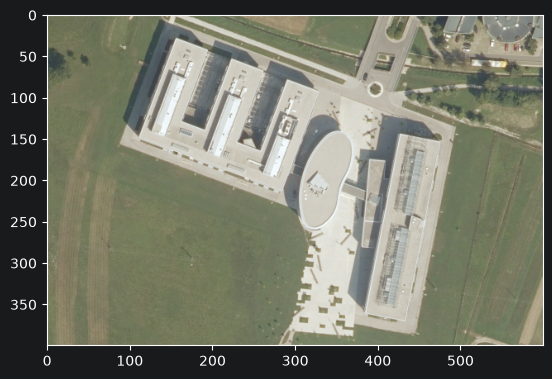

In [5]:
fri = before[458700:459000, 101200:101400]
print(fri['image'].shape)

plt.imshow(fri['image'].permute(1, 2, 0) / 255)

A nice thing we can do is resampling by simply providing a "stride" in meters here, like the stride in pyhon indexing. The following will give us the full area in 5m resolution (457250:459500:5, 100000:103000:5) and this nicely fits in a tiny image:

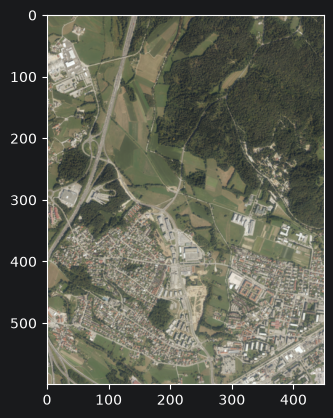

In [6]:
overview = before[457250:459500:5, 100000:103000:5]
plt.imshow(overview['image'].permute(1, 2, 0) / 255)

## Buildings as vectors

Building data is in vector shape and consists of many polygons. We use geopackage here, I'm not a geospatial expert so this might not be the obvious choice for some of you, but it works for what I want to show here and you can use I'd assume pretty much any vector file format.

`VectorDataset` turns the vector data in the back into masks for the sampled point that we ask for. In our case 1 is building and 0 is everything else. We only set the resolution, which we match to our ortho images.

Building file is in `labels` dir with name `buildings_2018.gpkg`. Let's again index at 458800:459000, 101200:101400.

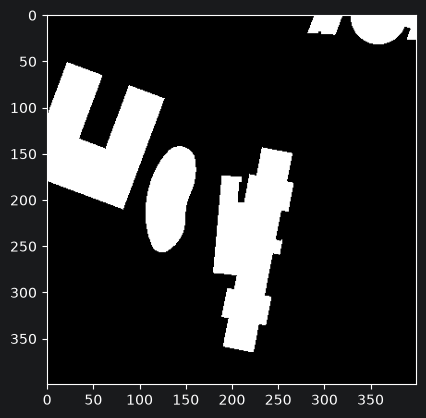

In [7]:
buildings = VectorDataset(PREPARED / 'labels/buildings_2018.gpkg', res=before.res)
sample = buildings[458800:459000, 101200:101400]
plt.imshow(sample['mask'], cmap='gray')

Okay now let's write a new custom dataset where we will load both images and labels, right?


Not really.... TorchGeo luckily enables combination of datasets using simple union `|` and intersection `&` operators. Since this is non temporal rgb dataset, the default intresection will work just fine here, so let's try to combin the two datasets and then visualise the stuff:

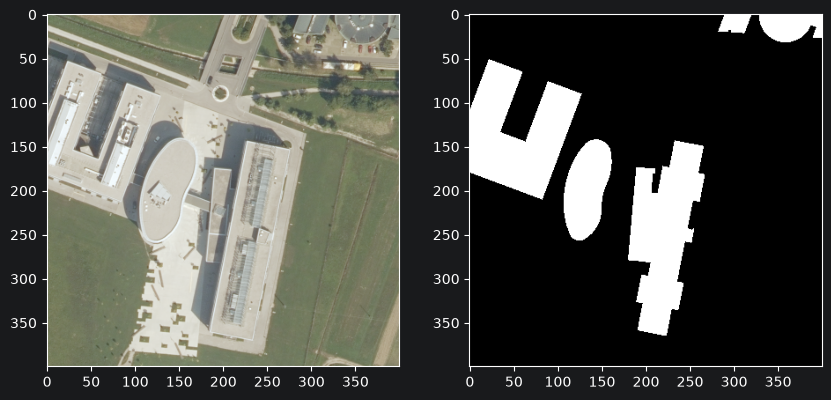

In [8]:
dataset = before & buildings

sample = dataset[458800:459000, 101200:101400]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(sample['image'].permute(1, 2, 0) / 255)
axes[1].imshow(sample['mask'], cmap='gray')

Now that's pretty awesome isn't it. But our end goal of this tutorial is change detection. So how do we get a dataset that will provide us with pair of images and a change mask?

There are multiple ways, we also provide change masks here, but the other option is to just use combination similarly as above.

Stacking multiple datasets of same kinds stacks them in channel dimension, so given two images `[H, W, C]`, we'll get `[H, W, 2*C]`. The order matters here, both for downstram logica as well as reprojection and resampling. Same logic follows for stacking masks.

But we do not want 2 masks and then let the model do stuff with them, so how do we produce a chang mask from the building segmentations on the fly? We use a simple transform function which will:
"unstack" 2018 and 2024 building masks and then compare them to get change labels. We then pass this to our final intersection dataset (we'll see what this class is below).

torch.Size([6, 256, 256]) torch.Size([256, 256])


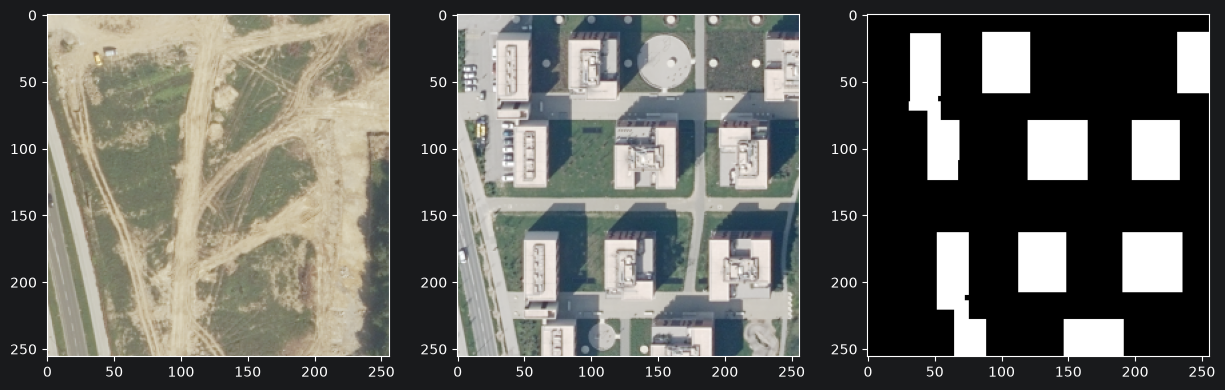

In [9]:
def to_change(sample):
    """Turns stacked 2018 and 2024 building masks into one change mask."""
    buildings_before, buildings_after = sample['mask'].chunk(2)
    sample['mask'] = (buildings_before != buildings_after).long()
    return sample


buildings_after = VectorDataset(PREPARED / 'labels/buildings_2024.gpkg', res=before.res)
pair = IntersectionDataset(before & after & buildings, buildings_after, transforms=to_change)

sample = pair[458400:458528, 100600:100728]
print(sample['image'].shape, sample['mask'].shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample['image'][:3].permute(1, 2, 0) / 255)
axes[1].imshow(sample['image'][3:].permute(1, 2, 0) / 255)
axes[2].imshow(sample['mask'], cmap='gray')

## Sentinel-2

Okay, good we now have hi-res RGB, but there's something we are forgetting here a bit right? Lots of applications use satellite stuff, and quite commonly that's Sentinel2. TorchGeo knows how to handle many sorts of data out of the box, and S2 is one of those. `Sentinel2` class finds bands and files by their name using the standard convention to get date (or you can do some custom stuff with regex if you for whatever reason do that :D). It also resamples 20m bands into 10m. We will pick 10 bands here (DEO requirement), that we will also use later and simply point the dataset to file sin `s2/year`.

In [10]:
BANDS = ('B04', 'B03', 'B02', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12')

s2_before = Sentinel2(PREPARED / 's2/2018', bands=BANDS, crs=before.crs, res=10)
s2_after = Sentinel2(PREPARED / 's2/2024', bands=BANDS, crs=before.crs, res=10)
s2_before.index

,filepath,geometry
datetime,,
"[2018-08-09 10:00:19, 2018-08-09 10:00:19.999999]",../data/prepared/s2/2018/T33TVM_20180809T10001...,"POLYGON ((459497.848 100000.153, 459497.848 10..."


S2 by default also has a valid `datetime` attribute. This means that if we do interesections with `&` operator, we run into issues as that intersection is also temporal. Let's try it anyway:

In [11]:
s2_failed = s2_before & s2_after
sample = s2_failed[458200:458840, 100400:101040]
print(sample['image'].shape)

# due to DEO indexing the first three bands are red, green and blue.
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow((sample['image'][:3] / 3000).clamp(0, 1).permute(1, 2, 0))
axes[1].imshow((sample['image'][10:13] / 3000).clamp(0, 1).permute(1, 2, 0))

RuntimeError: Datasets have no temporal intersection. Use `spatial_only=True` if you want to ignore temporal intersection

To get this working as expected, we can just do the following, using the same class as beofre and set our interesction to be spatial only:

torch.Size([20, 64, 64])


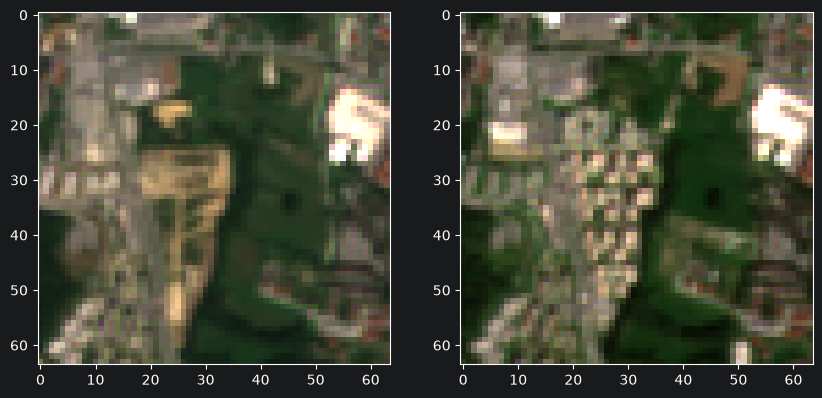

In [12]:
s2_pair = IntersectionDataset(s2_before, s2_after, spatial_only=True)

sample = s2_pair[458200:458840, 100400:101040]
print(sample['image'].shape)

# due to DEO indexing the first three bands are red, green and blue.
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow((sample['image'][:3] / 3000).clamp(0, 1).permute(1, 2, 0))
axes[1].imshow((sample['image'][10:13] / 3000).clamp(0, 1).permute(1, 2, 0))

What is nice here is that the labels work here too, let's try that and visualise 2018 building labels:

In [ ]:
buildings_10m = VectorDataset(PREPARED / 'labels/buildings_2018.gpkg', res=10)
sample = (s2_before & buildings_10m)[458200:458840, 100400:101040]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow((sample['image'][:3] / 3000).clamp(0, 1).permute(1, 2, 0))
axes[1].imshow(sample['mask'], cmap='gray')

## Train, val and test splits

If you remember from the intro, in ML we operate on different splits to get at least somewhat reliable numbers. Given we have a geospatial data here, we will do the splits in geospatial manner of course. So let's define the regions for train, val and test splits:

In [ ]:
train_roi = box(457250, 100000, 458250, 103000)
test_roi = box(458250, 100000, 458750, 103000)
val_roi = box(458750, 100000, 459500, 103000)

plt.imshow(overview['image'].permute(1, 2, 0) / 255, extent=(457250, 459500, 100000, 103000))
for name, roi in [('train', train_roi), ('test', test_roi), ('val', val_roi)]:
    plt.plot(*roi.exterior.xy)
    plt.text(roi.centroid.x, roi.centroid.y, name, color='red', ha='center')

Okay so now that we have regions, we will just use that in our train and test loops to sort of hack together the correct data, or let's rather do the splits before hand and make new classes or....

Yeah, sure thing... Not in TorchGeo :)

We just use *samplers* which will handle the sampling of patches. We have two options:
- `RandomPatchSampler` picks random patches inside an area, ideal for training.
- `GriddedPatchSampler` covers an area patch by patch, ideal for evaluation.

The PyTorch `DataLoader` then stacks the samples into batches, just like in the introduction.

Let's make our train sampler that will sample random patches inside the training region. And then also gridded sampler that gives us all patches over the test region.

In [ ]:
sampler = RandomPatchSampler(pair, size=256, length=100, roi=train_roi)
loader = DataLoader(pair, sampler=sampler, batch_size=8)

batch = next(iter(loader))
print(batch['image'].shape, batch['mask'].shape)

In [ ]:
sampler = GriddedPatchSampler(pair, size=256, roi=test_roi)
print(len(sampler))